# 03 · Análise exploratória

**Projeto Integrador** · Jeanderson Soares Mingorança  
**Fase do roadmap:** 3 · Escopo: somente a base comum (DA-017)

**Pergunta:** entre 2023 e 2025, como se modificaram o vale diurno e a rampa do fim da tarde da carga observada e da carga residual no SIN e nos subsistemas, e onde essas mudanças foram mais intensas?

**Regras de recorte** (DA-018 a DA-021):
- comparações entre anos usam **maio a dezembro**, porque a série solar muda de patamar em 29/04/2023;
- dias atípicos (incidentes de registro e o apagão de 15/08/2023) ficam **fora**;
- perfis horários usam **dias úteis** (sem fins de semana e feriados).

Cada figura tem título com a conclusão, nível, recorte, unidade e fonte. As funções de gráfico estão em `src/visualizacao.py`.

## 1. Ambiente e dados

In [1]:
from pathlib import Path
import sys

# Localiza a raiz do projeto (pasta com pyproject.toml) a partir do diretório atual,
# para que o notebook funcione aberto de notebooks/ ou da raiz.
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

PASTA_TABELAS = RAIZ / "resultados" / "tabelas"
PASTA_FIGURAS = RAIZ / "resultados" / "figuras"
PASTA_PROCESSADOS = RAIZ / "dados" / "processados"
for pasta in (PASTA_TABELAS, PASTA_FIGURAS, PASTA_PROCESSADOS):
    pasta.mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__, "| numpy:", np.__version__, "| matplotlib:", matplotlib.__version__)
print("Raiz do projeto:", RAIZ.name)

Python: 3.12.10
pandas: 3.0.5 | numpy: 2.5.3 | matplotlib: 3.11.2
Raiz do projeto: JeandersonMingoranca_ProjetoIntegrador


In [2]:
from src import visualizacao as viz
viz.estilo()

arquivo_horario = PASTA_PROCESSADOS / "base_horaria.parquet"
arquivo_diario = PASTA_PROCESSADOS / "indicadores_diarios.parquet"
if not (arquivo_horario.exists() and arquivo_diario.exists()):
    raise FileNotFoundError("Execute antes notebooks/02_preprocessamento.ipynb para gerar dados/processados/.")

diarios = pd.read_parquet(arquivo_diario)
horario = pd.read_parquet(arquivo_horario).merge(
    diarios[["id_subsistema", "data", "dia_atipico", "mes_comparavel"]],
    on=["id_subsistema", "data"], how="left", validate="many_to_one")
assert horario["dia_atipico"].notna().all()

horario_cmp = horario[horario["mes_comparavel"] & ~horario["dia_atipico"]]
diarios_cmp = diarios[diarios["mes_comparavel"] & ~diarios["dia_atipico"]]
print("Horas (recorte comparável):", len(horario_cmp), "| dias × nível:", len(diarios_cmp))
diarios_cmp.groupby(["id_subsistema", "ano"]).size().unstack()

Horas (recorte comparável): 87600 | dias × nível: 3650


ano,2023,2024,2025
id_subsistema,,,
N,244,243,243
NE,244,243,243
S,244,243,243
SE,244,243,243
SIN,244,243,243


## 2. Perfil horário do SIN: o vale do meio-dia (H1, H2) — Figura 1

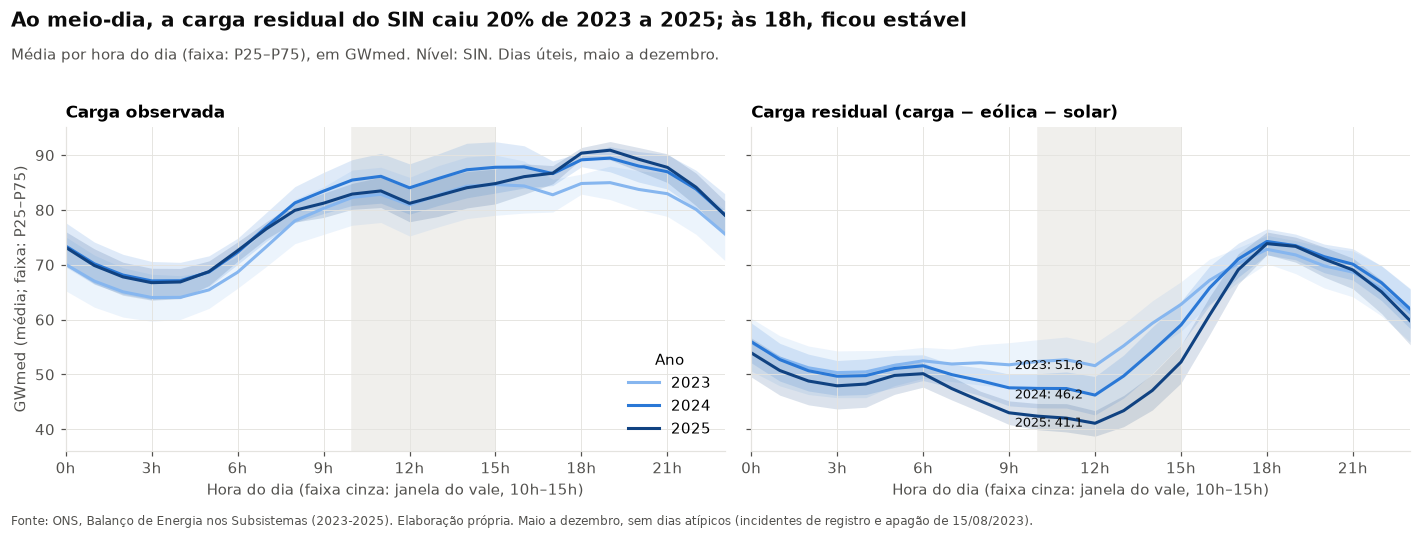

In [3]:
perfil_sin = viz.perfil_horario(horario_cmp[horario_cmp["dia_util"]], "SIN")
fig = viz.fig_perfil_horario(
    perfil_sin,
    "Ao meio-dia, a carga residual do SIN caiu 20% de 2023 a 2025; às 18h, ficou estável",
    "Média por hora do dia (faixa: P25–P75), em GWmed. Nível: SIN. Dias úteis, maio a dezembro.",
    rodape_extra="Maio a dezembro, sem dias atípicos (incidentes de registro e apagão de 15/08/2023).")
fig.savefig(PASTA_FIGURAS / "03_fig1_perfil_horario_sin.png", bbox_inches="tight")
plt.show()

In [4]:
tabela_perfil = (perfil_sin.pivot_table(index=["variavel", "hora"], columns="ano", values="media")
                .loc[(slice(None), [3, 12, 18, 19]), :].round(1))
tabela_perfil["var_%_23_25"] = (100 * (tabela_perfil[2025] / tabela_perfil[2023] - 1)).round(1)
residual = perfil_sin[perfil_sin["variavel"] == "carga_residual"].pivot_table(index="hora", columns="ano", values="media")
print("Hora do mínimo da carga residual:", residual.idxmin().to_dict())
tabela_perfil

Hora do mínimo da carga residual: {2023: 3, 2024: 12, 2025: 12}


ano                  2023  2024  2025  var_%_23_25
variavel       hora                               
carga_residual 3     50.3  49.7  47.9         -4.8
               12    51.6  46.2  41.1        -20.3
               18    72.8  74.3  73.9          1.5
               19    71.8  73.5  73.4          2.2
val_carga      3     64.0  67.1  66.7          4.2
               12    80.9  84.0  81.2          0.4
               18    84.8  89.1  90.4          6.6
               19    85.0  89.5  90.9          6.9

**Leitura (Figura 1):**
- **Carga residual:** ao meio-dia, cai de **51,6 GW (2023) para 46,2 GW (2024) e 41,1 GW (2025)**, cerca de −20%. Às 18h fica praticamente estável (72,8 → 73,9 GW). A diferença entre o vale e o pico do fim da tarde, portanto, aumenta.
- **Mudança de forma:** em 2023, o mínimo diário da carga residual ocorria **de madrugada (3h)**; em 2024 e 2025 passa para o **meio-dia (12h)**. É o formato de "curva do pato".
- **Carga observada (H1):** entre 2023 e 2025, cresce **+0,4% às 12h** e **+6,9% às 19h**. A carga das horas solares cresce menos que a da noite, o que é compatível com a hipótese de consumo atendido por geração local (MMGD) durante o dia. A base, porém, não mede a MMGD; temperatura e atividade econômica também influenciam.

## 3. Mês × hora: onde e quando o vale é mais fundo — Figura 2

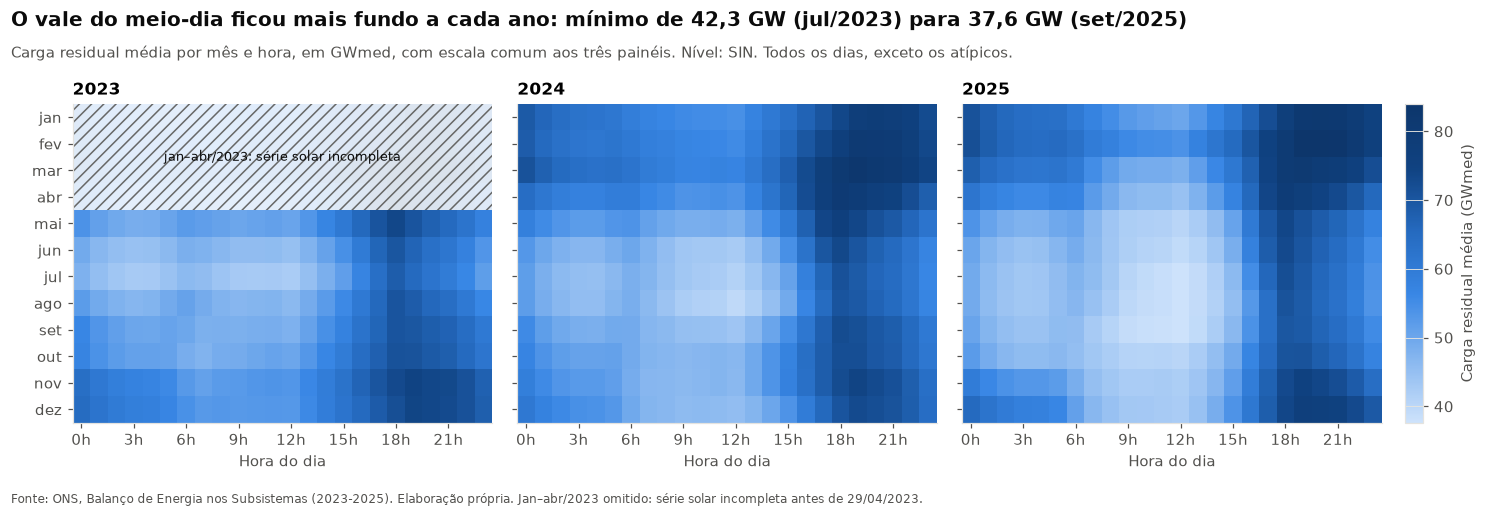

In [5]:
fig = viz.fig_heatmap(
    horario[~horario["dia_atipico"]], "SIN",
    "O vale do meio-dia ficou mais fundo a cada ano: mínimo de 42,3 GW (jul/2023) para 37,6 GW (set/2025)",
    "Carga residual média por mês e hora, em GWmed, com escala comum aos três painéis. Nível: SIN. Todos os dias, exceto os atípicos.",
    rodape_extra="Jan–abr/2023 omitido: série solar incompleta antes de 29/04/2023.")
fig.savefig(PASTA_FIGURAS / "03_fig2_heatmap_mes_hora_sin.png", bbox_inches="tight")
plt.show()

In [6]:
minimos = {}
for ano in viz.CORES_ANO:
    matriz = viz.matriz_mes_hora(horario[~horario["dia_atipico"]], "SIN", ano)
    if ano == 2023:
        matriz = matriz.loc[5:]
    (mes, hora), valor = matriz.stack().idxmin(), matriz.stack().min()
    minimos[ano] = {"mes": mes, "hora": hora, "carga_residual_GWmed": round(valor, 1)}
pd.DataFrame(minimos).T

,mes,hora,carga_residual_GWmed
2023,7.0,12.0,42.3
2024,8.0,12.0,39.5
2025,9.0,12.0,37.6


**Leitura (Figura 2):** a faixa mais clara (carga residual baixa) fica entre **10h e 14h**, de **julho a outubro**, e se alarga a cada ano. O mínimo mensal-horário cai de 42,3 GW (julho de 2023, 12h) para 39,5 GW (agosto de 2024) e **37,6 GW (setembro de 2025)**. Essa época combina estação seca, sol forte e ventos intensos no Nordeste, que é a **janela crítica** a priorizar.

## 4. Rampa do fim da tarde por subsistema (H2, H4) — Figura 3

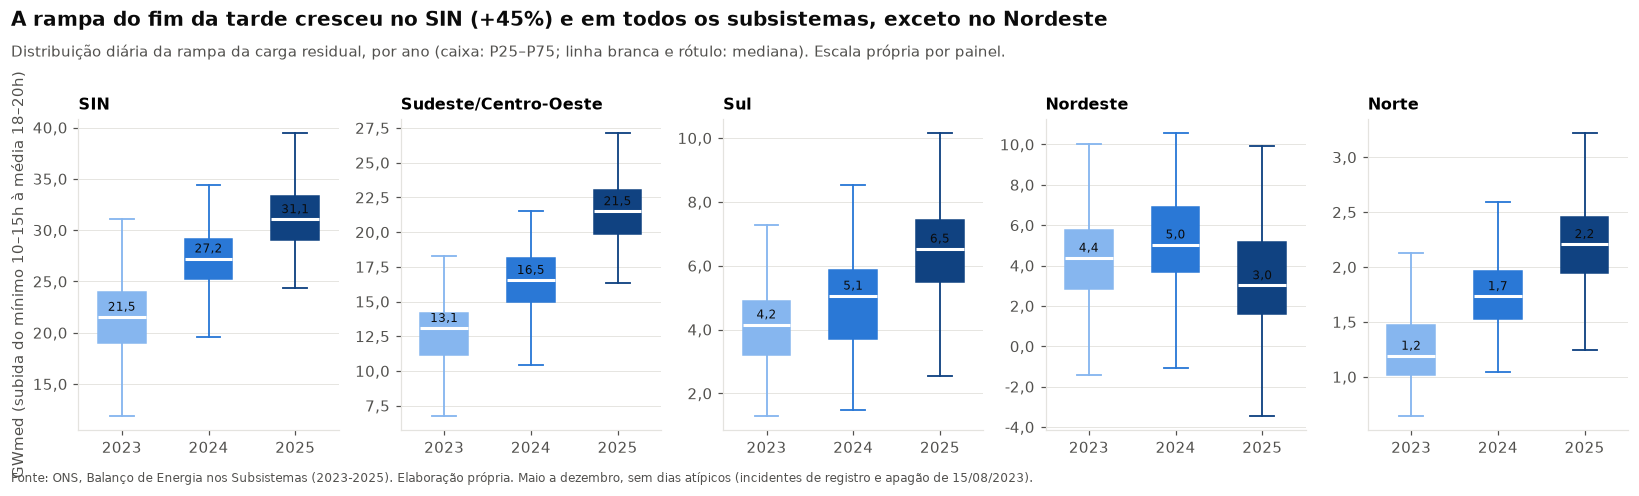

In [7]:
fig = viz.fig_distribuicao_por_ano(
    diarios_cmp, "rampa_tarde", "GWmed (subida do mínimo 10–15h à média 18–20h)",
    "A rampa do fim da tarde cresceu no SIN (+45%) e em todos os subsistemas, exceto no Nordeste",
    "Distribuição diária da rampa da carga residual, por ano (caixa: P25–P75; linha branca e rótulo: mediana). Escala própria por painel.",
    rodape_extra="Maio a dezembro, sem dias atípicos (incidentes de registro e apagão de 15/08/2023).", casas=1)
fig.savefig(PASTA_FIGURAS / "03_fig3_rampa_tarde.png", bbox_inches="tight")
plt.show()

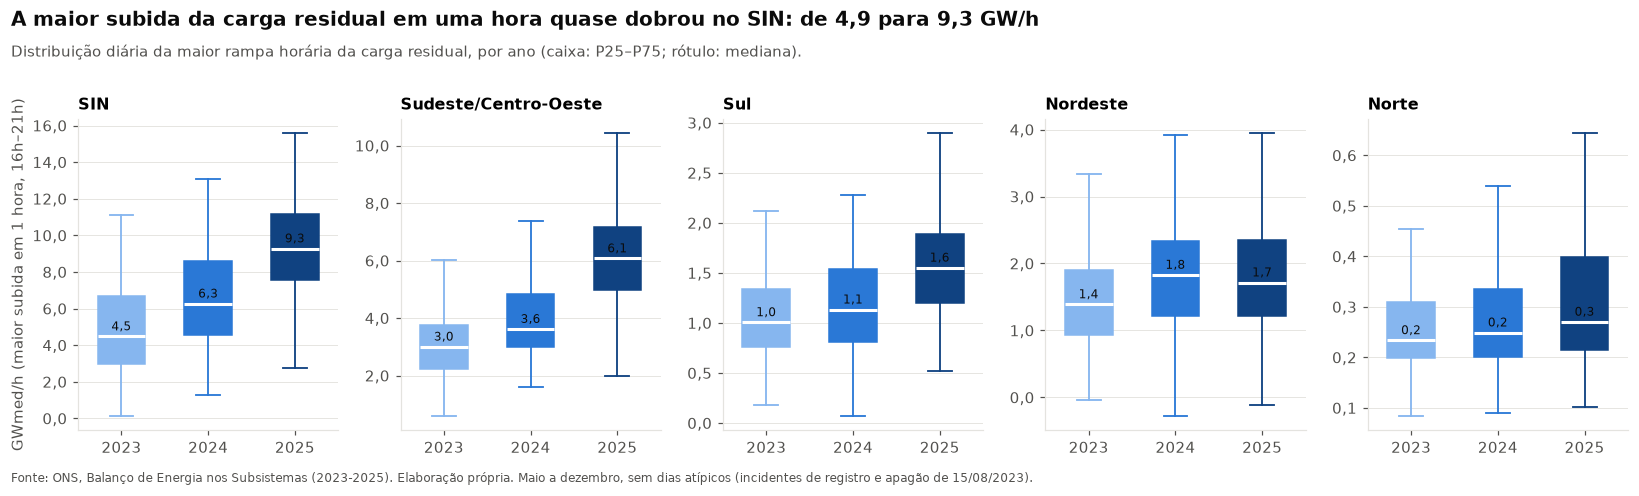

In [8]:
fig = viz.fig_distribuicao_por_ano(
    diarios_cmp, "maior_rampa_horaria", "GWmed/h (maior subida em 1 hora, 16h–21h)",
    "A maior subida da carga residual em uma hora quase dobrou no SIN: de 4,9 para 9,3 GW/h",
    "Distribuição diária da maior rampa horária da carga residual, por ano (caixa: P25–P75; rótulo: mediana).",
    rodape_extra="Maio a dezembro, sem dias atípicos (incidentes de registro e apagão de 15/08/2023).", casas=1)
fig.savefig(PASTA_FIGURAS / "03_fig3b_maior_rampa_horaria.png", bbox_inches="tight")
plt.show()

**Leitura (Figura 3):** a rampa média do fim da tarde cresce de 2023 para 2025 no **SIN (+45%, de 21,5 para 31,2 GW)**, no **SE (+67%)**, no **S (+56%)** e no **N (+78%, embora em nível baixo)**. No **NE**, cai em 2025 (−25%): ali a carga residual é **negativa** ao meio-dia (eólica + solar acima da carga; o NE exporta), e a rampa depende também do perfil do vento ao entardecer. A **maior rampa horária** do SIN quase dobra (+92%), exigindo mais da flexibilidade das fontes controláveis no fim da tarde.

## 5. Horas de carga residual baixa (H3) — Figura 4

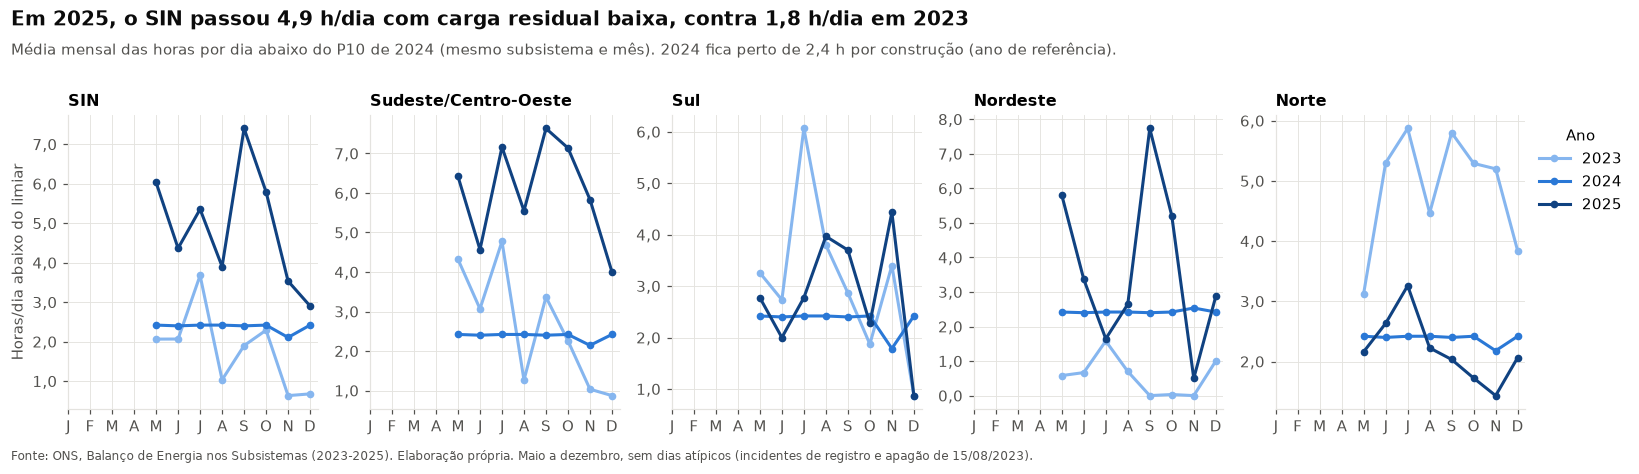

In [9]:
fig = viz.fig_mensal_por_ano(
    diarios_cmp, "horas_residual_baixa", "Horas/dia abaixo do limiar",
    "Em 2025, o SIN passou 4,9 h/dia com carga residual baixa, contra 1,8 h/dia em 2023",
    "Média mensal das horas por dia abaixo do P10 de 2024 (mesmo subsistema e mês). 2024 fica perto de 2,4 h por construção (ano de referência).",
    rodape_extra="Maio a dezembro, sem dias atípicos (incidentes de registro e apagão de 15/08/2023).")
fig.savefig(PASTA_FIGURAS / "03_fig4_horas_residual_baixa.png", bbox_inches="tight")
plt.show()

In [10]:
dias_com_hora_baixa = (diarios_cmp.assign(tem_hora_baixa=diarios_cmp["horas_residual_baixa"] > 0)
                       .groupby(["id_subsistema", "ano"])["tem_hora_baixa"].mean().unstack().mul(100).round(0))
dias_com_hora_baixa.loc[viz.ORDEM]

ano,2023,2024,2025
id_subsistema,,,
SIN,26.0,40.0,74.0
SE,37.0,38.0,89.0
S,39.0,33.0,48.0
NE,16.0,56.0,72.0
N,84.0,52.0,49.0


**Leitura (Figura 4):** no SIN, a média sobe de **1,8 h/dia (2023) para 4,9 h/dia (2025)**, e a fração de dias com pelo menos uma hora de carga residual baixa sobe de **26% para 74%**. O aumento é maior no **SE** (2,6 → 6,0 h/dia; 89% dos dias em 2025) e no **NE** (0,6 → 3,7 h/dia). Em **N** e **S** não há aumento: no Norte, a carga cresceu mais que a geração eólica e solar local. Os picos de 2025 ocorrem em **maio, julho, setembro e outubro**.

*Nota:* "carga residual baixa" indica **condição propícia a excesso de oferta**, não corte de geração (curtailment), que a base não mede.

## 6. Intercâmbio nas horas de carga residual baixa (H5) — Figura 6

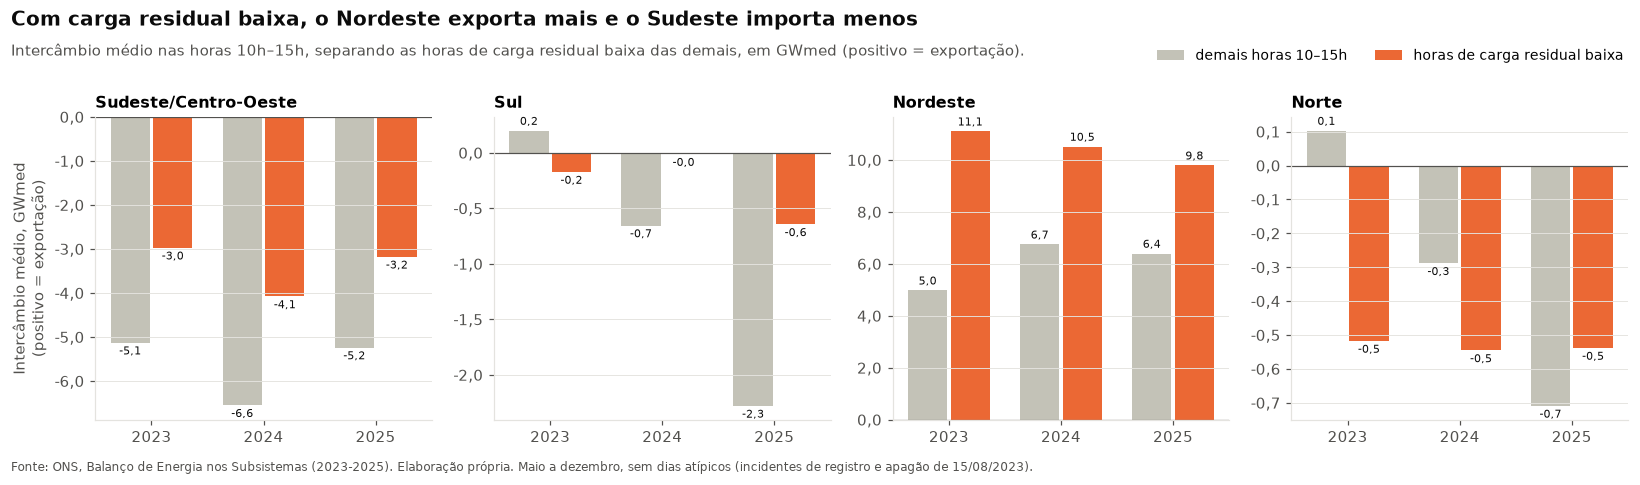

In [11]:
tabela_intercambio = viz.intercambio_por_condicao(horario_cmp)
fig = viz.fig_intercambio(
    tabela_intercambio,
    "Com carga residual baixa, o Nordeste exporta mais e o Sudeste importa menos",
    "Intercâmbio médio nas horas 10h–15h, separando as horas de carga residual baixa das demais, em GWmed (positivo = exportação).",
    rodape_extra="Maio a dezembro, sem dias atípicos (incidentes de registro e apagão de 15/08/2023).")
fig.savefig(PASTA_FIGURAS / "03_fig6_intercambio.png", bbox_inches="tight")
plt.show()

In [12]:
tabela_intercambio.pivot_table(index=["id_subsistema", "ano"], columns="residual_baixa",
                               values=["intercambio_medio", "horas"]).round(0)

horas         intercambio_medio         
residual_baixa       False   True              False    True 
id_subsistema ano                                            
N             2023   856.0   608.0             103.0   -518.0
              2024  1033.0   425.0            -289.0   -546.0
              2025  1028.0   430.0            -709.0   -538.0
NE            2023  1402.0    62.0            4981.0  11103.0
              2024  1270.0   188.0            6748.0  10516.0
              2025  1326.0   132.0            6396.0   9795.0
S             2023  1202.0   262.0             199.0   -174.0
              2024  1185.0   273.0            -655.0    -13.0
              2025  1057.0   401.0           -2280.0   -645.0
SE            2023  1171.0   293.0           -5128.0  -2973.0
              2024  1070.0   388.0           -6550.0  -4079.0
              2025   452.0  1006.0           -5238.0  -3178.0

**Leitura (Figura 6):** nas horas de carga residual baixa, o **NE exporta ~10 GW**, contra ~6–7 GW nas demais horas solares. O **SE**, importador, **importa ~2 GW a menos**. O Sul passa a importar fortemente em 2025 fora dessas horas. O padrão é coerente com o NE escoando excedente renovável para o SE ao meio-dia, o que é relevante para os limites de intercâmbio. É uma relação **descritiva**: o intercâmbio depende também de despacho, hidrologia e restrições elétricas.

## 7. Tabela-resumo 2023 → 2025 (base da tabela 5.2 do roteiro)

In [ ]:
resumo = viz.tabela_resumo(diarios_cmp)
resumo.to_csv(PASTA_TABELAS / "03_resumo_indicadores_2023_2025.csv", index=False)
tabela_intercambio.to_csv(PASTA_TABELAS / "03_intercambio_residual_baixa.csv", index=False)
dias_com_hora_baixa.to_csv(PASTA_TABELAS / "03_pct_dias_com_hora_baixa.csv")
tabela_perfil.to_csv(PASTA_TABELAS / "03_perfil_horario_sin_horas_chave.csv")
(resumo.assign(**{c: resumo[c].round(2) for c in ["2023", "2024", "2025", "var_abs_23_25", "var_pct_23_25"]})
 .pivot_table(index="indicador", columns="nivel", values="var_pct_23_25")[viz.ORDEM])

nivel,SIN,SE,S,NE,N
indicador,,,,,
carga_residual_min,-17.78,-19.74,-10.91,-58.90,2.68
horas_residual_baixa,172.41,129.49,-8.33,546.22,-54.75
indice_vale,-2.81,-2.24,-3.64,-5.52,0.16
maior_rampa_horaria,91.91,92.08,44.52,25.49,24.20
rampa_tarde,45.34,66.82,56.47,-25.37,78.42


: 

## 8. Síntese da exploração (para a tabela 5.2)

| # | Evidência | Resultado (maio a dezembro, sem dias atípicos) | Hipótese |
|---|---|---|---|
| 1 | Perfil horário do SIN | Carga residual às 12h: 51,6 → 41,1 GW (−20%); às 18h, estável (~73 GW). O mínimo diário passa das 3h (2023) para as 12h (2024–2025) | H1, H2 compatíveis |
| 2 | Heatmap mês × hora | Vale mais fundo entre 10h e 14h, de julho a outubro; mínimo de 42,3 → 37,6 GW | Janela crítica |
| 3 | Rampa do fim da tarde | SIN +45% (21,5 → 31,2 GW); SE +67%; S +56%; N +78%; NE −25%; maior rampa horária do SIN +92% | H2 compatível; H4 (não uniforme) |
| 4 | Horas de carga residual baixa | SIN 1,8 → 4,9 h/dia; dias com ≥1 h: 26% → 74%; maior no SE e no NE; N e S sem aumento | H3 compatível; H4 |
| 5 | Intercâmbio | NE exporta ~10 GW nas horas de carga residual baixa (contra ~6 GW); SE importa ~2 GW a menos | H5 compatível (descritivo) |

**Prioridades que emergem:** SE e NE; **julho a outubro**; **10h–14h** (vale) e **17h–20h** (rampa). A Fase 4 verifica se as diferenças entre os anos se sustentam com controle de mês e tipo de dia e com erros robustos à autocorrelação.

**Limites:** são médias descritivas de três anos; clima, hidrologia e economia também variam entre os anos; a base não mede MMGD nem cortes de geração.